<a href="https://colab.research.google.com/github/nileve-teo/INSTRUMENTACION-BIOMEDICA/blob/main/LABORATORIO_N_%C2%B0_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Simulador de sEMG a partir de registros reales

Etapa A — Lectura de registros

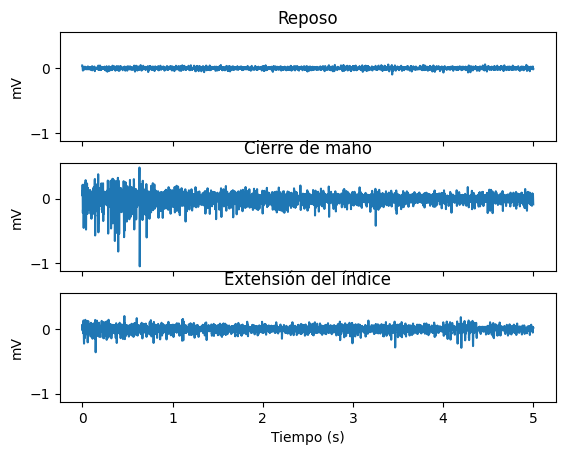

In [2]:

!pip install wfdb
import wfdb
import numpy as np
import matplotlib.pyplot as plt
carpeta = "grabmyo/1.1.0/Session1/session1_participant1"
gestos = {"Reposo": 17, "Cierre de mano": 16, "Extensión del índice": 9}
canal = 11 # canal F12 → índice 11 en Python
senales = {}
for nombre_g, k in gestos.items():
    rec = wfdb.rdrecord(f"session1_participant1_gesture{k}_trial1", pn_dir=carpeta)
    senales[nombre_g] = rec.p_signal[:, canal]
fig, ax = plt.subplots(3, 1, sharex=True, sharey=True)
for a, (nombre_g, x) in zip(ax, senales.items()):
    a.plot(np.arange(len(x)) / rec.fs, x)
    a.set_title(nombre_g)
    a.set_ylabel("mV")
ax[-1].set_xlabel("Tiempo (s)")
plt.show()


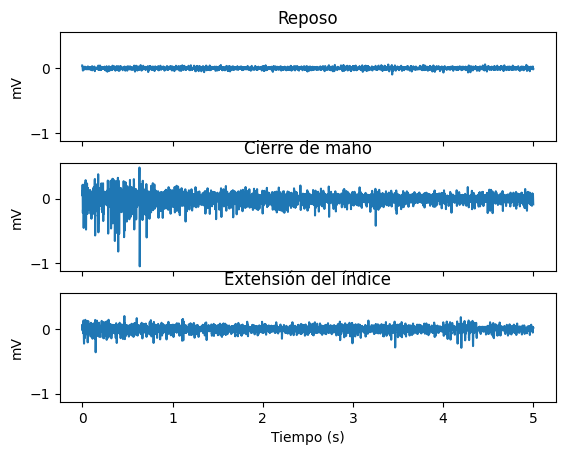

In [3]:
import wfdb
import numpy as np
import matplotlib.pyplot as plt

carpeta = "grabmyo/1.1.0/Session1/session1_participant1"

gestos = {
    "Reposo": 17,
    "Cierre de mano": 16,
    "Extensión del índice": 9
}

canal = 11  # Canal F12 → índice 11 en Python
senales = {}

for nombre_g, k in gestos.items():
    rec = wfdb.rdrecord(
        f"session1_participant1_gesture{k}_trial1",
        pn_dir=carpeta
    )
    senales[nombre_g] = rec.p_signal[:, canal]

fig, ax = plt.subplots(3, 1, sharex=True, sharey=True)

for a, (nombre_g, x) in zip(ax, senales.items()):
    a.plot(np.arange(len(x)) / rec.fs, x)
    a.set_title(nombre_g)
    a.set_ylabel("mV")

ax[-1].set_xlabel("Tiempo (s)")
plt.show()

Etapa B. Preparación de la señal para el DAC

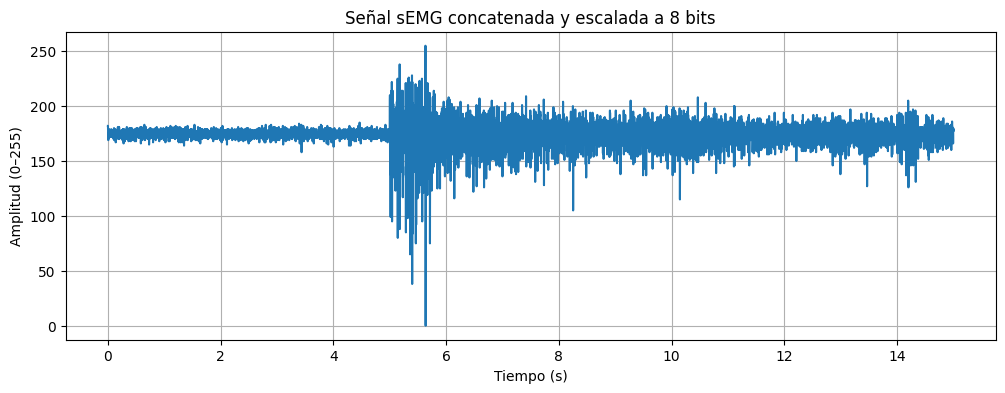

Número de muestras: 30720
Frecuencia de muestreo: 2048 Hz
Duración: 15.0 segundos
Archivo semg.h generado correctamente.


In [4]:
# ============================================
# ETAPA B - CONSTRUCCIÓN DE LA SECUENCIA
# ============================================

# Concatenar las tres señales en el orden indicado
senal_completa = np.concatenate([
    senales["Reposo"],
    senales["Cierre de mano"],
    senales["Extensión del índice"]
])

# ============================================
# ESCALAMIENTO GLOBAL A 0 - 255
# ============================================

# Escalamiento lineal de toda la secuencia a valores entre 0 y 255

senal_min = np.min(senal_completa)
senal_max = np.max(senal_completa)

senal_8bits = np.round(
    (senal_completa - senal_min) *
    255 / (senal_max - senal_min)
).astype(np.uint8)

# Parámetros de reproducción
FS_SEMG = 2048
N_SEMG = len(senal_8bits)

# ============================================
# GRÁFICA DE LA SECUENCIA ESCALADA
# ============================================

# Graficar la señal escalada
tiempo = np.arange(N_SEMG) / FS_SEMG

plt.figure(figsize=(12, 4))
plt.plot(tiempo, senal_8bits)
plt.xlabel("Tiempo (s)")
plt.ylabel("Amplitud (0–255)")
plt.title("Señal sEMG concatenada y escalada a 8 bits")
plt.grid()
plt.show()

# Exportar el archivo semg.h
with open("semg.h", "w") as f:
    f.write("#ifndef SEMG_H\n")
    f.write("#define SEMG_H\n\n")
    f.write("#include <stdint.h>\n\n")
    f.write("const uint8_t SEMG[] = {\n")

    for i in range(0, N_SEMG, 16):
        f.write("  " + ", ".join(map(str, senal_8bits[i:i+16])) + ",\n")

    f.write("};\n\n")
    f.write(f"const uint32_t N_SEMG = {N_SEMG};\n")
    f.write(f"const uint16_t FS_SEMG = {FS_SEMG};\n\n")
    f.write("#endif\n")

print("Número de muestras:", N_SEMG)
print("Frecuencia de muestreo:", FS_SEMG, "Hz")
print("Duración:", N_SEMG / FS_SEMG, "segundos")
print("Archivo semg.h generado correctamente.")

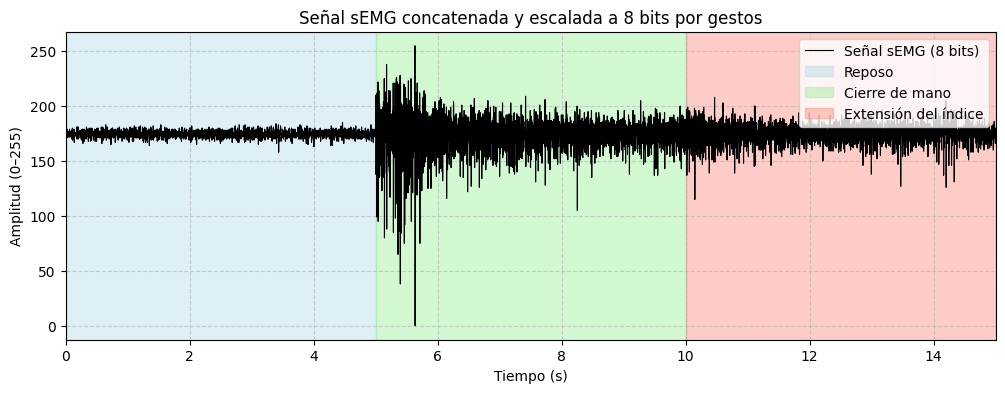

In [5]:
# Concatenar las tres señales en el orden indicado
senal_completa = np.concatenate([
    senales["Reposo"],
    senales["Cierre de mano"],
    senales["Extensión del índice"]
])

# Escalamiento global al rango de 0 a 255
senal_min = np.min(senal_completa)
senal_max = np.max(senal_completa)

senal_8bits = np.round(
    (senal_completa - senal_min) *
    255 / (senal_max - senal_min)
).astype(np.uint8)

# Parámetros de reproducción
FS_SEMG = 2048
N_SEMG = len(senal_8bits)

# Tiempos de duración individuales de cada tramo
t_reposo = len(senales["Reposo"]) / FS_SEMG
t_cierre = len(senales["Cierre de mano"]) / FS_SEMG
t_extension = len(senales["Extensión del índice"]) / FS_SEMG

# Puntos de corte acumulados en tiempo
t0 = 0
t1 = t_reposo
t2 = t1 + t_cierre
t3 = t2 + t_extension

# Graficar la señal escalada con regiones sombreadas
tiempo = np.arange(N_SEMG) / FS_SEMG

plt.figure(figsize=(12, 4))
plt.plot(tiempo, senal_8bits, color='black', linewidth=0.8, label="Señal sEMG (8 bits)")

# Sombras coloreadas para cada tramo
plt.axvspan(t0, t1, color='lightblue', alpha=0.4, label="Reposo")
plt.axvspan(t1, t2, color='lightgreen', alpha=0.4, label="Cierre de mano")
plt.axvspan(t2, t3, color='salmon', alpha=0.4, label="Extensión del índice")

# Configuración de etiquetas y leyenda
plt.xlabel("Tiempo (s)")
plt.ylabel("Amplitud (0–255)")
plt.title("Señal sEMG concatenada y escalada a 8 bits por gestos")
plt.legend(loc="upper right")
plt.grid(True, linestyle="--", alpha=0.6)
plt.xlim(t0, t3)
plt.show()

Descargar el archivo semg.h

In [7]:
from google.colab import files
files.download("semg.h")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Etapa C: reproducción de la señal sEMG mediante el DAC del ESP32 clásico.